# Clustering de estaciones MiBici (2024–2025)

**Proyecto:** TC5061 · Equipo 37
**Autor:** Alan Hernández
**Objetivo:** responder P3: ¿qué grupos de estaciones comparten patrones de uso y dónde se ubican en la ciudad?

La idea es describir cada estación por la forma en que se usa a lo largo del día, tanto en salidas como en llegadas, y ver qué estaciones se parecen entre sí. Para eso se arma un perfil horario por estación, se reduce con PCA y se agrupa con K-Means. Al final los grupos se llevan al mapa para ver en qué zonas de la ciudad cae cada uno.

> Si el perfil funciona, la función que lo construye pasaría a `MiBici/features.py` como `station_usage_profile`.

## 1. Configuración

In [25]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from MiBici.config import FIGURES_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)

SEED = 37
MIN_VIAJES = 500  # salidas + llegadas en todo el periodo
FIG_DIR = FIGURES_DIR / "p3"
FIG_DIR.mkdir(parents=True, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Carga de datos

Para esta pregunta basta con las fechas y las estaciones de origen y destino, así que solo se leen esas columnas y los datos personales se quedan fuera.

In [26]:
TRIPS_PATH = INTERIM_DATA_DIR / "mibici_2024_2025.csv"
STATIONS_PATH = INTERIM_DATA_DIR / "nomenclatura_2026_09.csv"

trips = pd.read_csv(
    TRIPS_PATH,
    usecols=["Inicio_del_viaje", "Fin_del_viaje", "Origen_Id", "Destino_Id"],
    dtype={"Origen_Id": "int32", "Destino_Id": "int32"},
    parse_dates=["Inicio_del_viaje", "Fin_del_viaje"],
)
stations = pd.read_csv(STATIONS_PATH, encoding="utf-8")
print(f"viajes: {len(trips):,} · estaciones en nomenclatura: {len(stations)}")
stations.head()

viajes: 9,177,953 · estaciones en nomenclatura: 484


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


## 3. Limpieza

Se usan los mismos umbrales que en el notebook 1.0. Los viajes de un minuto o menos suelen ser bicis que no se desengancharon bien, y los de más de tres horas casi siempre son errores o bicis que no se devolvieron a tiempo. También se quitan los viajes que terminan en la misma estación donde empezaron, porque no dicen nada sobre el movimiento entre zonas.

In [27]:
dur = (trips["Fin_del_viaje"] - trips["Inicio_del_viaje"]).dt.total_seconds() / 60
mask = dur.between(1, 180, inclusive="neither") & (trips["Origen_Id"] != trips["Destino_Id"])
print(f"se conservan {mask.mean():.1%} de los viajes")
trips = trips.loc[mask].reset_index(drop=True)

se conservan 93.7% de los viajes


## 4. Perfil de uso por estación

Para cada estación se cuentan las salidas según la hora de inicio y las llegadas según la hora de fin, separando entre semana y fin de semana, lo que da cuatro bloques de 24 horas. Cada bloque se normaliza para que sume 1; de esta forma una estación chica y una grande con el mismo ritmo diario quedan juntas, y el tamaño se agrega después como una variable aparte (`log_volumen`).

In [28]:
def hourly_counts(ts, station, kind):
    df = pd.DataFrame({
        "estacion_id": station.values,
        "dia": np.where(ts.dt.dayofweek >= 5, "finde", "semana"),
        "hora": ts.dt.hour.values,
    })
    out = df.pivot_table(index="estacion_id", columns=["dia", "hora"], aggfunc="size", fill_value=0)
    # De madrugada no hay viajes; se fuerzan las 24 columnas
    full = pd.MultiIndex.from_product([["finde", "semana"], range(24)], names=["dia", "hora"])
    out = out.reindex(columns=full, fill_value=0)
    out.columns = [f"{kind}_{d}_{h:02d}" for d, h in out.columns]
    return out


sal = hourly_counts(trips["Inicio_del_viaje"], trips["Origen_Id"], "sal")
lle = hourly_counts(trips["Fin_del_viaje"], trips["Destino_Id"], "lle")
counts = sal.join(lle, how="outer").fillna(0)
counts.shape

(373, 96)

In [29]:
# Métricas por estación para interpretar los grupos
def block(prefix):
    return counts.filter(like=prefix)


def hours(df, hs):
    return df[[c for c in df.columns if int(c[-2:]) in hs]].sum(axis=1)


n_dias_semana = trips["Inicio_del_viaje"].dt.normalize().loc[lambda s: s.dt.dayofweek < 5].nunique()
n_dias = trips["Inicio_del_viaje"].dt.normalize().nunique()

sal_tot, lle_tot = block("sal_").sum(axis=1), block("lle_").sum(axis=1)
AM, PM = range(6, 10), range(17, 21)
sal_sem, lle_sem = block("sal_semana"), block("lle_semana")

summary = pd.DataFrame({
    "viajes": sal_tot + lle_tot,
    "viajes_dia": (sal_tot + lle_tot) / n_dias,
    # > 0 recibe más bicis de las que salen
    "balance": (lle_tot - sal_tot) / (lle_tot + sal_tot),
    "pct_finde": (block("_finde_").sum(axis=1)) / (sal_tot + lle_tot),
    # Mismo balance pero solo en hora pico, entre semana
    "balance_am": (hours(lle_sem, AM) - hours(sal_sem, AM)) / (hours(lle_sem, AM) + hours(sal_sem, AM)),
    "balance_pm": (hours(lle_sem, PM) - hours(sal_sem, PM)) / (hours(lle_sem, PM) + hours(sal_sem, PM)),
    "pct_pico": (hours(sal_sem, list(AM) + list(PM)) + hours(lle_sem, list(AM) + list(PM)))
    / (sal_sem.sum(axis=1) + lle_sem.sum(axis=1)),
})
summary["viajes"].describe()

count       373.000000
mean      46117.008043
std       45299.697994
min         228.000000
25%       16390.000000
50%       33358.000000
75%       60469.000000
max      401392.000000
Name: viajes, dtype: float64

In [30]:
con_coord = summary.index.isin(stations["id"])
activas = summary["viajes"] >= MIN_VIAJES
print(f"estaciones con viajes: {len(summary)} · sin coordenadas: {(~con_coord).sum()} · bajo {MIN_VIAJES} viajes: {(~activas).sum()}")
keep = summary.index[con_coord & activas]
summary = summary.loc[keep]
counts = counts.loc[keep]
len(keep)

estaciones con viajes: 373 · sin coordenadas: 0 · bajo 500 viajes: 1


372

In [31]:
blocks = ["sal_semana", "lle_semana", "sal_finde", "lle_finde"]
profile = pd.concat(
    [counts.filter(like=b).pipe(lambda d: d.div(d.sum(axis=1).replace(0, 1), axis=0)) for b in blocks],
    axis=1,
)
features = profile.assign(
    log_volumen=np.log1p(summary["viajes_dia"]),
    balance=summary["balance"],
    pct_finde=summary["pct_finde"],
)
features.shape

(372, 99)

## 5. Escalado y PCA

Las horas contiguas están muy correlacionadas entre sí, así que antes de agrupar se estandarizan las variables y se aplica PCA conservando el 90 % de la varianza. Esto también ayuda a que el ruido de las horas con poco uso no pese tanto en las distancias.

componentes: 47 · varianza explicada: 90.4%


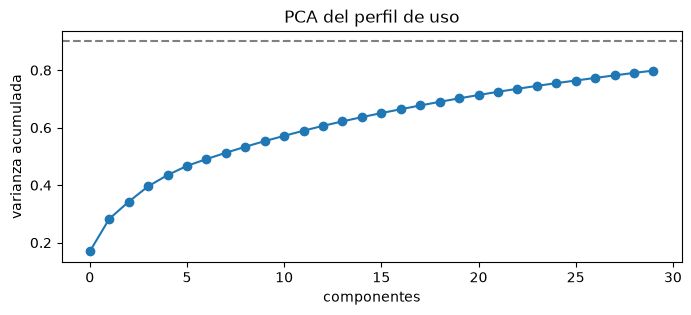

In [32]:
X_std = StandardScaler().fit_transform(features)
pca = PCA(n_components=0.90, random_state=SEED).fit(X_std)
X = pca.transform(X_std)
print(f"componentes: {pca.n_components_} · varianza explicada: {pca.explained_variance_ratio_.sum():.1%}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(np.cumsum(PCA(random_state=SEED).fit(X_std).explained_variance_ratio_[:30]), marker="o")
ax.axhline(0.90, ls="--", c="grey")
ax.set(xlabel="componentes", ylabel="varianza acumulada", title="PCA del perfil de uso");

## 6. Selección de k

Se corre K-Means con k de 2 a 10 y se comparan la inercia, la silueta y el índice de Davies-Bouldin. Además se calcula el ARI contra un clustering jerárquico de Ward con el mismo k: si dos métodos distintos llegan a grupos parecidos, es más probable que esos grupos existan en los datos y no sean un efecto del algoritmo.

In [33]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    rows.append({
        "k": k,
        "inercia": km.inertia_,
        "silueta": silhouette_score(X, km.labels_),
        "davies_bouldin": davies_bouldin_score(X, km.labels_),
        "ari_vs_ward": adjusted_rand_score(km.labels_, ward),
        "min_tamano": np.bincount(km.labels_).min(),
    })
k_eval = pd.DataFrame(rows).set_index("k")
k_eval.round(3)

,inercia,silueta,davies_bouldin,ari_vs_ward,min_tamano
k,,,,,
2,26643.381,0.132,2.409,0.641,165
3,24471.385,0.140,2.092,0.673,32
4,23457.327,0.071,2.605,0.423,37
5,22626.753,0.074,2.541,0.510,26
6,21921.921,0.069,2.563,0.448,20
7,21499.921,0.073,2.240,0.468,1
8,21013.991,0.078,2.091,0.500,1
9,20602.806,0.051,2.518,0.412,3
10,20177.631,0.067,2.258,0.334,1


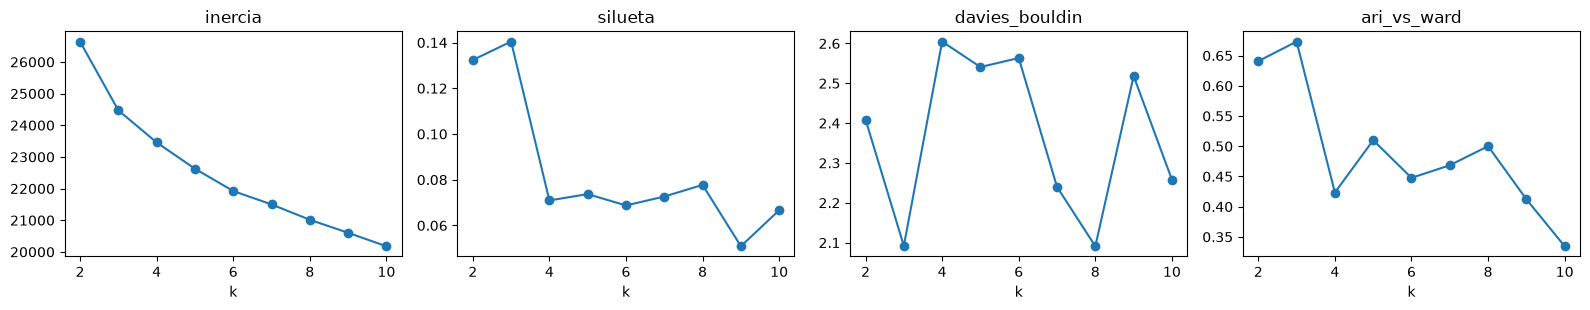

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, col in zip(axes, ["inercia", "silueta", "davies_bouldin", "ari_vs_ward"]):
    k_eval[col].plot(ax=ax, marker="o", title=col)
    ax.set_xlabel("k")
plt.tight_layout()
fig.savefig(FIG_DIR / "seleccion_k.png", dpi=150)

In [35]:
# k entre 3 y 8; puntaje = silueta + ARI - DB, normalizados
cand = k_eval.loc[3:8]
norm = lambda s: (s - s.min()) / (s.max() - s.min())
score = norm(cand["silueta"]) + norm(cand["ari_vs_ward"]) - norm(cand["davies_bouldin"])
K = int(score.idxmax())
print("puntaje compuesto:", score.round(2).to_dict(), "| k elegido:", K)

puntaje compuesto: {3: 2.0, 4: -0.97, 5: -0.46, 6: -0.82, 7: -0.05, 8: 0.43} | k elegido: 3


## 7. Modelo final

In [36]:
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
summary["cluster"] = km.labels_
summary["cluster"].value_counts().sort_index()

cluster
0    192
1     33
2    147
Name: count, dtype: int64

### 7.1 Perfiles horarios por grupo

En las gráficas la línea continua son las salidas y la punteada las llegadas.

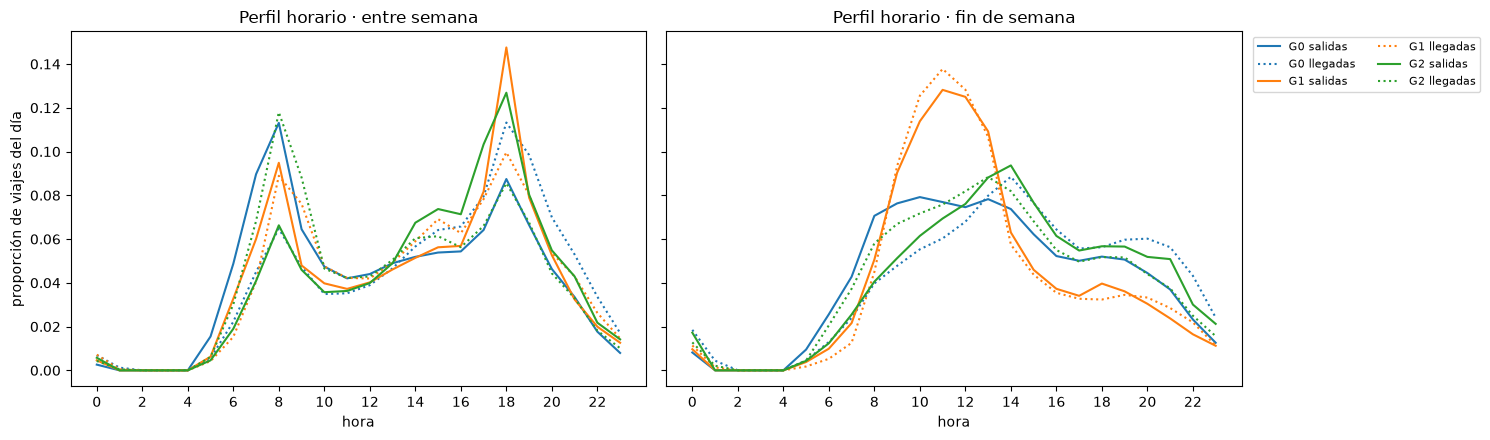

In [37]:
colors = plt.cm.tab10(np.arange(K))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, dia in zip(axes, ["semana", "finde"]):
    for c in range(K):
        sub = profile.loc[summary["cluster"] == c]
        ax.plot(range(24), sub.filter(like=f"sal_{dia}").mean().values, c=colors[c], label=f"G{c} salidas")
        ax.plot(range(24), sub.filter(like=f"lle_{dia}").mean().values, c=colors[c], ls=":", label=f"G{c} llegadas")
    ax.set(title=f"Perfil horario · {'entre semana' if dia == 'semana' else 'fin de semana'}", xlabel="hora", xticks=range(0, 24, 2))
axes[0].set_ylabel("proporción de viajes del día")
axes[1].legend(ncol=2, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
fig.savefig(FIG_DIR / "perfiles_cluster.png", dpi=150, bbox_inches="tight")

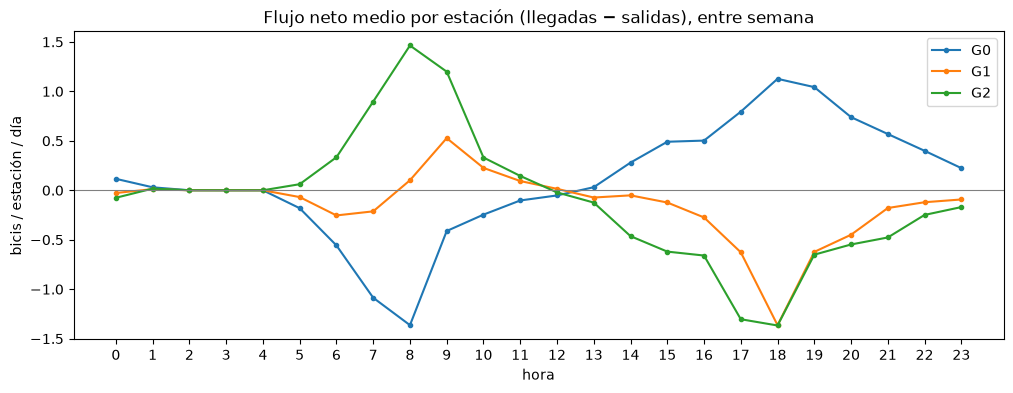

In [38]:
fig, ax = plt.subplots(figsize=(12, 4))
for c in range(K):
    sub = counts.loc[summary["cluster"] == c]
    neto = (sub.filter(like="lle_semana").values - sub.filter(like="sal_semana").values).sum(axis=0)
    ax.plot(range(24), neto / (n_dias_semana * len(sub)), c=colors[c], marker=".", label=f"G{c}")
ax.axhline(0, c="grey", lw=0.8)
ax.set(title="Flujo neto medio por estación (llegadas − salidas), entre semana", xlabel="hora", ylabel="bicis / estación / día", xticks=range(24))
ax.legend()
fig.savefig(FIG_DIR / "flujo_neto_cluster.png", dpi=150, bbox_inches="tight");

### 7.2 Resumen y etiqueta de cada grupo

In [39]:
res = summary.groupby("cluster").agg(
    estaciones=("viajes", "size"),
    viajes_dia_mediana=("viajes_dia", "median"),
    balance=("balance", "mean"),
    balance_am=("balance_am", "mean"),
    balance_pm=("balance_pm", "mean"),
    pct_pico=("pct_pico", "mean"),
    pct_finde=("pct_finde", "mean"),
)
res.round(3)

,estaciones,viajes_dia_mediana,balance,balance_am,balance_pm,pct_pico,pct_finde
cluster,,,,,,,
0,192,44.547,0.018,-0.262,0.170,0.561,0.197
1,33,21.040,-0.108,-0.147,-0.192,0.570,0.284
2,147,55.114,-0.061,0.203,-0.216,0.552,0.188


In [40]:
# Umbrales relativos a la mediana de todas las estaciones
ref = summary[["viajes_dia", "pct_finde", "pct_pico"]].median()


def etiqueta(r):
    partes = []
    if r["balance_am"] > 0.15 and r["balance_pm"] < -0.15:
        partes.append("destino laboral/escolar")
    elif r["balance_am"] < -0.15 and r["balance_pm"] > 0.15:
        partes.append("origen residencial")
    else:
        partes.append("mixto")
    if r["pct_finde"] > ref["pct_finde"] * 1.15:
        partes.append("recreativo/fin de semana")
    if r["viajes_dia_mediana"] > ref["viajes_dia"] * 1.5:
        partes.append("alta demanda")
    elif r["viajes_dia_mediana"] < ref["viajes_dia"] * 0.6:
        partes.append("baja demanda")
    return " · ".join(partes)


res["etiqueta"] = res.apply(etiqueta, axis=1)
summary["etiqueta"] = summary["cluster"].map(res["etiqueta"])
res[["estaciones", "viajes_dia_mediana", "balance_am", "balance_pm", "pct_finde", "etiqueta"]].round(3)

,estaciones,viajes_dia_mediana,balance_am,balance_pm,pct_finde,etiqueta
cluster,,,,,,
0,192,44.547,-0.262,0.170,0.197,origen residencial
1,33,21.040,-0.147,-0.192,0.284,mixto · recreativo/fin de semana · baja demanda
2,147,55.114,0.203,-0.216,0.188,destino laboral/escolar


## 8. Ubicación

Las coordenadas vienen de la nomenclatura de estaciones. El nombre de cada estación empieza con un prefijo (`GDL`, `ZPN`, `TLQ`) que indica el municipio, y para tener una idea de qué tan céntrica es cada estación se calcula su distancia a Plaza de Armas.

In [41]:
geo = stations.set_index("id")[["name", "latitude", "longitude", "dpcapacity"]]
st = summary.join(geo, how="inner")
st["municipio"] = st["name"].str.extract(r"\(([A-Z]+)-")[0].fillna("OTRO")

CENTRO = (20.6767, -103.3475)  # Plaza de Armas


def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


st["dist_centro_km"] = haversine_km(st["latitude"], st["longitude"], *CENTRO)
st[["name", "municipio", "cluster", "etiqueta", "dist_centro_km"]].head()

,name,municipio,cluster,etiqueta,dist_centro_km
estacion_id,,,,,
2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,GDL,0,origen residencial,1.155940
3,(GDL-002) C. Colonias / Av. Niños héroes,GDL,2,destino laboral/escolar,2.194001
4,(GDL-003) C. Vidrio / Av. Chapultepec,GDL,2,destino laboral/escolar,2.380083
5,(GDL-004) C. Ghilardi /C. Miraflores,GDL,0,origen residencial,2.299418
6,(GDL-005) C. San Diego /Calzada Independencia,GDL,0,origen residencial,0.980935


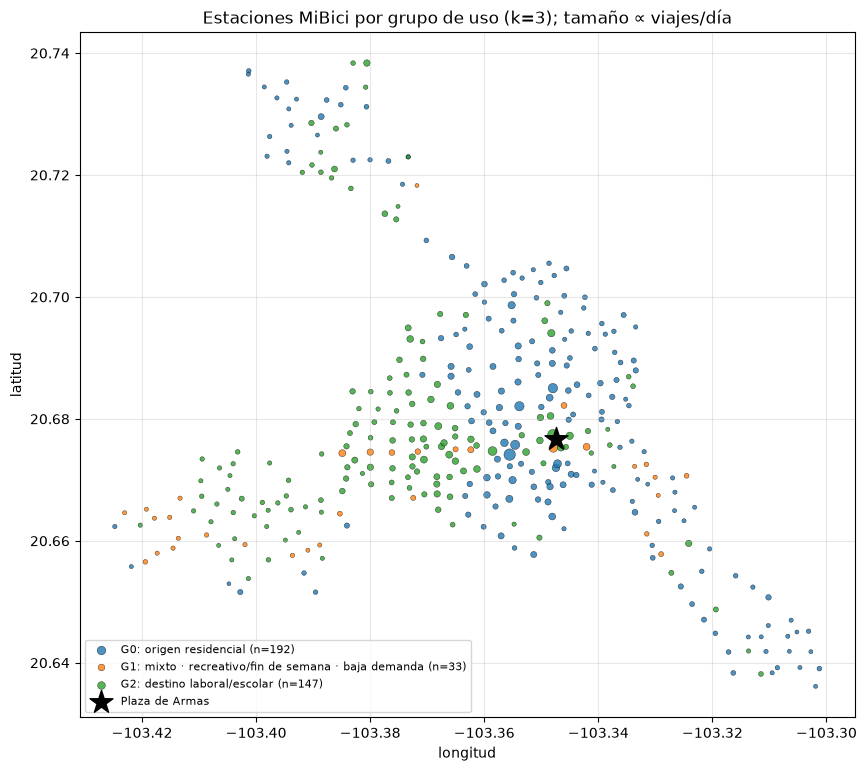

In [42]:
fig, ax = plt.subplots(figsize=(10, 10))
size = 8 + 60 * (st["viajes_dia"] / st["viajes_dia"].max())
for c in range(K):
    sub = st[st["cluster"] == c]
    ax.scatter(sub["longitude"], sub["latitude"], s=size[sub.index], color=colors[c], alpha=0.8,
               edgecolor="k", linewidth=0.3, label=f"G{c}: {res.loc[c, 'etiqueta']} (n={len(sub)})")
ax.scatter(CENTRO[1], CENTRO[0], marker="*", s=300, c="k", label="Plaza de Armas")
ax.set(title=f"Estaciones MiBici por grupo de uso (k={K}); tamaño ∝ viajes/día", xlabel="longitud", ylabel="latitud")
ax.set_aspect(1 / np.cos(np.radians(CENTRO[0])))
ax.legend(loc="lower left", fontsize=8)
ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "mapa_clusters.png", dpi=150, bbox_inches="tight")

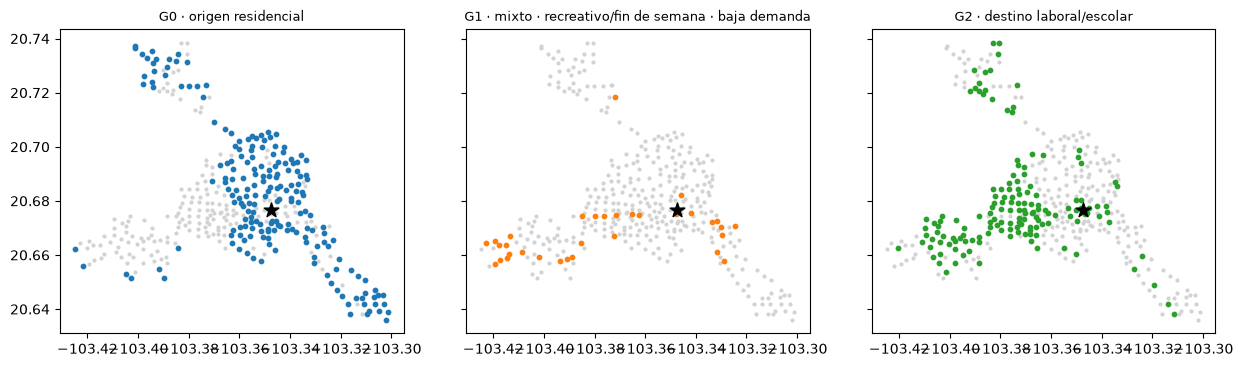

In [43]:
ncols = min(K, 4)
nrows = int(np.ceil(K / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.2 * nrows), sharex=True, sharey=True, squeeze=False)
for ax in axes.flat[K:]:
    ax.axis("off")
for c, ax in zip(range(K), axes.flat):
    ax.scatter(st["longitude"], st["latitude"], s=4, c="lightgrey")
    sub = st[st["cluster"] == c]
    ax.scatter(sub["longitude"], sub["latitude"], s=10, color=colors[c])
    ax.scatter(CENTRO[1], CENTRO[0], marker="*", s=120, c="k")
    ax.set_title(f"G{c} · {res.loc[c, 'etiqueta']}", fontsize=9)
    ax.set_aspect(1 / np.cos(np.radians(CENTRO[0])))
plt.tight_layout()
fig.savefig(FIG_DIR / "mapa_clusters_paneles.png", dpi=150, bbox_inches="tight")

In [44]:
# % de estaciones de cada municipio por grupo
mun = pd.crosstab(st["municipio"], st["cluster"], normalize="index").mul(100).round(1)
mun["n"] = st["municipio"].value_counts()
display(mun)
st.groupby("cluster").agg(
    dist_centro_mediana_km=("dist_centro_km", "median"),
    lat_media=("latitude", "mean"),
    lon_media=("longitude", "mean"),
    capacidad_media=("dpcapacity", "mean"),
).round(3)

cluster,0,1,2,n
municipio,,,,
GDL,53.9,7.4,38.7,282
TLQ,86.7,0.0,13.3,15
ZPN,36.0,16.0,48.0,75


,dist_centro_mediana_km,lat_media,lon_media,capacidad_media
cluster,,,,
0,2.242,20.682,-103.351,17.391
1,3.897,20.668,-103.377,17.182
2,3.222,20.679,-103.375,16.279


In [45]:
# 5 estaciones más cercanas al centroide de cada grupo
dist = km.transform(X)
rep = (
    pd.DataFrame({"cluster": km.labels_, "d": dist[np.arange(len(X)), km.labels_]}, index=summary.index)
    .join(geo["name"])
    .sort_values("d")
    .groupby("cluster")
    .head(5)
    .sort_values(["cluster", "d"])
)
rep

,cluster,d,name
estacion_id,,,
156,0,2.507366,(GDL-089) C. Juan Álvarez / C. Cruz Verde
13,0,3.340619,(GDL-011) C. Garibaldi / C. Frías
180,0,3.413231,(GDL-113) C. Ghilardi / C. Arista
170,0,3.452940,(GDL-103) J. Clemente Orozco /C. Jesús García
69,0,3.756124,(GDL-067) Calzada Federalismo / C. Vidrio
220,1,5.681753,(GDL-153) C. Crepúsculo / Av. Tonantzin
306,1,5.910015,(ZPN-066) C. Cuauhtémoc / Av. Tepeyac
56,1,5.935435,(GDL-054) Av. Juárez / Calz. Independencia
230,1,6.149128,(GDL-163) C. Corregidora / Blvrd. García B.


## 9. Robustez

Para revisar que los grupos no dependan de la semilla, se compara el modelo final contra diez corridas con semillas distintas usando el ARI.

In [46]:
aris = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X)) for s in range(10)]
pd.Series(aris).describe().round(3)

count    10.000
mean      0.963
std       0.014
min       0.940
25%       0.952
50%       0.962
75%       0.975
max       0.980
dtype: float64

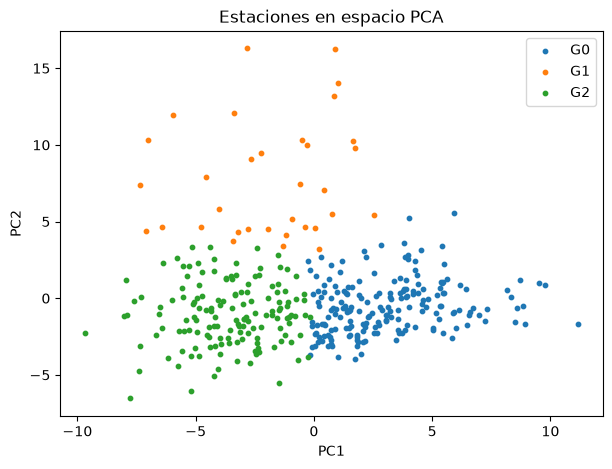

In [47]:
fig, ax = plt.subplots(figsize=(7, 5))
for c in range(K):
    m = km.labels_ == c
    ax.scatter(X[m, 0], X[m, 1], s=10, color=colors[c], label=f"G{c}")
ax.set(xlabel="PC1", ylabel="PC2", title="Estaciones en espacio PCA")
ax.legend();

## 10. Exportar asignación

In [48]:
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT = PROCESSED_DATA_DIR / "p3_estaciones_cluster.csv"
st[["name", "municipio", "latitude", "longitude", "cluster", "etiqueta", "viajes_dia", "balance", "balance_am", "balance_pm", "pct_finde"]].to_csv(OUT)
OUT

PosixPath('/home/alan-hernandez/Documents/MNA/TC5061/TC5061-Proyecto-Equipo37/data/processed/p3_estaciones_cluster.csv')

## 11. Respuesta a P3

Las 372 estaciones con al menos 500 viajes se agrupan mejor en tres perfiles (k = 3, silueta 0.14, ARI contra Ward 0.67). Con más grupos la calidad baja y aparecen grupos de una a tres estaciones. En MLflow (`train_p3.py`) las métricas salen en 0.125 de silueta y 0.71 de ARI porque ahí se calculan sobre el perfil completo y no sobre las componentes de PCA, para poder compararlas con el baseline; los grupos son los mismos.

| Grupo | Estaciones | Viajes/día (mediana) | % fin de semana |
|---|---|---|---|
| G0 origen residencial | 192 | 45 | 20 % |
| G2 destino laboral/escolar | 147 | 55 | 19 % |
| G1 mixto/recreativo | 33 | 21 | 28 % |

- **G0 (residencial):** las bicis salen en la mañana y regresan en la tarde. Está en el Centro Histórico, el oriente y norte de Guadalajara y el corredor hacia Tlaquepaque.
- **G2 (laboral/escolar):** lo contrario, las bicis llegan en la mañana y se van en la tarde. Es el grupo con más viajes y se ubica al poniente del centro (Americana, Chapultepec, Providencia) y en Zapopan.
- **G1 (recreativo):** poca demanda y más uso en fin de semana. Sigue el eje Av. Juárez–Vallarta y algunas estaciones del poniente.

G0 y G2 se complementan, así que el rebalanceo de la mañana debería llevar bicis de G2 a G0 y el de la tarde al revés; esto sirve como insumo para P2. La silueta es baja, por lo que los grupos se traslapan un poco, sobre todo en el centro.